# Spectral Analysis

Expected input: a `.tbl` file generated from AstroImageJ after plotting along a line along an observed spectrum.  

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import ascii
from astropy.modeling import models, fitting



In [3]:
data = ascii.read('HD28794Spectra.tbl')

In [6]:
data

Distance_(pixels),Count
int64,float64
0,21833.0
1,31516.7265625
2,39847.1875
3,45923.79296875
4,48191.3671875
5,44713.90234375
6,35747.375
7,24177.345703125
8,14114.9765625


(350.0, 1200.0)

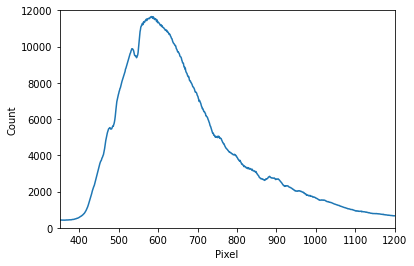

In [14]:
plt.plot(data['Distance_(pixels)'],data['Count'])
plt.xlabel('Pixel')
plt.ylabel('Count')
plt.ylim(0,12000)
plt.xlim(350,1200)

## Wavelength Calibration

We should convert pixels to wavelength with a scaling factor. 

You calculated one for the HW on spectra, however that is only approximate. It is better to identify some spectral features and calculate the scaling from this data.

We expect H𝛂 at 656nm to be a prominent absorption feature in most stars (around 700 pixels based on Stellar Spectrum Assignment) and it comes with Hbeta (486nm, around 550 pixels) and Hdelta (434nm about 490 pixels) although the atmospheric absorption feature at 760 nm (about 850 pixels) is also often very prominent. 

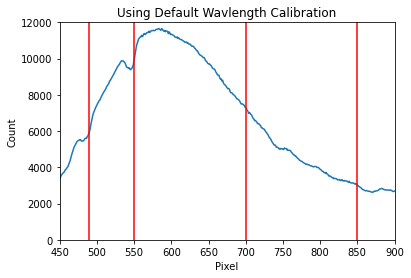

In [19]:
plt.plot(data['Distance_(pixels)'],data['Count'])
plt.xlabel('Pixel')
plt.ylabel('Count')
plt.title('Using Default Wavlength Calibration (not well lined up)')
plt.ylim(0,12000)
plt.xlim(450,900)
plt.plot([490,490],[0,12000],color='red')
plt.plot([550,550],[0,12000],color='red')
plt.plot([700,700],[0,12000],color='red')
plt.plot([850,850],[0,12000],color='red')

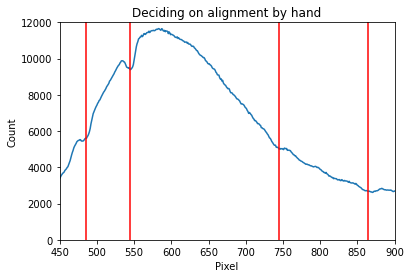

In [22]:
#I ran this cell a bunch of times tweaking the pixel values for the 
#four absorption features until I was happy with the alignment. 
#There's probably a fancy automated way to do this, but this worked. 

plt.plot(data['Distance_(pixels)'],data['Count'])
plt.xlabel('Pixel')
plt.ylabel('Count')
plt.title('Deciding on alignment by hand')
plt.ylim(0,12000)
plt.xlim(450,900)
plt.plot([485,485],[0,12000],color='red')
plt.plot([545,545],[0,12000],color='red')
plt.plot([745,745],[0,12000],color='red')
plt.plot([865,865],[0,12000],color='red')

The slope of this line is the conversion factor from pixel to wavelength
Model: Linear1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
          slope            intercept     
    ------------------ ------------------
    0.8562835660580017 18.852846401718505


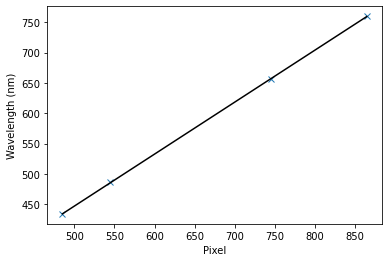

In [29]:
pixel=[485,545,745,865]
wavelength=[434,486,656,760]

#Set linear model
line_orig = models.Linear1D(slope=1.0, intercept=0.5)
# initialize a linear fitter
fit = fitting.LinearLSQFitter()
# initialize a linear model
line_init = models.Linear1D()

# fit the data with the fitter
fitted_line = fit(line_init, pixel, wavelength)

plt.plot(pixel, wavelength,'x')
plt.plot(pixel, fitted_line(pixel), 'k-', label='Fitted Model')

plt.xlabel('Pixel')
plt.ylabel('Wavelength (nm)')

print('The slope of this line is the conversion factor from pixel to wavelength')
print(fitted_line)


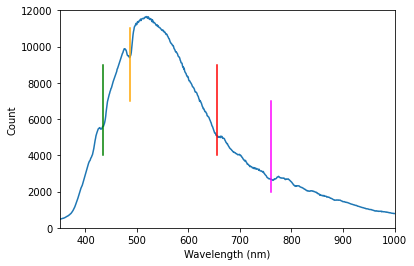

In [38]:
data_wavelength=fitted_line(data['Distance_(pixels)'])
#wavelength=[434,486,656,760]

plt.plot(data_wavelength,data['Count'])
plt.xlabel('Wavelength (nm)')
plt.ylabel('Count')
plt.ylim(0,12000)
plt.xlim(350,1000)
plt.plot([434,434],[4000,9000],color='green')
plt.plot([486,486],[7000,11000],color='orange')
plt.plot([656,656],[4000,9000],color='red')
plt.plot([760,760],[2000,7000],color='magenta')